# 04 · Candidate features + first Folium map (train)

In [1]:
import sys, os
from pathlib import Path
_root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "pathsnap").is_dir()), None)
if _root is None:
    raise RuntimeError("src/pathsnap not found: unzip all zips of the set into the same pathsnap/ folder")
sys.path.insert(0, str(_root / "src")); os.chdir(_root / "notebooks")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathsnap import io, labels, features, viz

FIG = "../outputs/figures"

In [2]:
dfs = []
for tid in io.list_trips("train")[:20]:
    tr = io.load_trip("train", tid)
    lab, _ = labels.align_route(tr)
    df, _ = features.candidate_table(tr, lab, step=5)
    dfs.append(df)
df = pd.concat(dfs, ignore_index=True)
print(df.shape, "positive rate:", df.y.mean().round(3))
df.head()

(62171, 22) positive rate: 0.16


,trip,point,arc,dist,rank,dist_gap,dist_ratio,head_diff,move,speed,...,alen,n_cand,n_cand30,ctx_prev,ctx_next,ctx_mean,out_deg,in_deg,has_rev,y
0,00000001,0,64973,0.717462,0,0.000000,0.417746,0.683862,92.902089,0.0,...,293.233475,8,2,0.717462,6.101189,2.512038,1,1,0,1
1,00000001,0,117639,15.011202,1,14.293740,8.740338,179.247735,92.902089,0.0,...,1020.419974,8,2,15.011202,9.450850,13.157751,1,1,0,0
2,00000001,0,2641,32.199252,2,31.481790,18.748156,0.554973,92.902089,0.0,...,425.045485,8,2,32.199252,180.243648,81.547384,1,1,0,0
3,00000001,0,50652,92.292651,3,91.575189,53.737802,170.236316,92.902089,0.0,...,169.056632,8,2,92.292651,70.845354,85.143552,3,2,1,0
4,00000001,0,53932,92.292651,4,91.575189,53.737802,9.763684,92.902089,0.0,...,169.056632,8,2,92.292651,70.845354,85.143552,2,3,1,0


In [3]:
df[features.FEATURES].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
dist,62171.0,25.38,23.89,0.00,6.88,17.30,36.87,99.99
rank,62171.0,3.04,2.27,0.00,1.00,3.00,5.00,7.00
dist_gap,62171.0,18.95,23.27,0.00,0.00,10.13,29.28,99.33
dist_ratio,62171.0,5.83,8.77,0.00,0.91,2.41,6.97,94.07
head_diff,62171.0,88.07,67.11,0.00,17.09,86.38,160.34,180.00
move,62171.0,45.18,51.11,0.11,10.04,20.58,68.62,782.44
speed,62171.0,13.67,11.35,0.00,5.97,10.06,17.84,112.06
dt,62171.0,1.27,6.39,1.00,1.00,1.00,1.00,458.00
frac,62171.0,0.50,0.42,0.00,0.00,0.49,1.00,1.00
alen,62171.0,156.02,318.16,0.96,25.93,60.26,146.42,4666.38


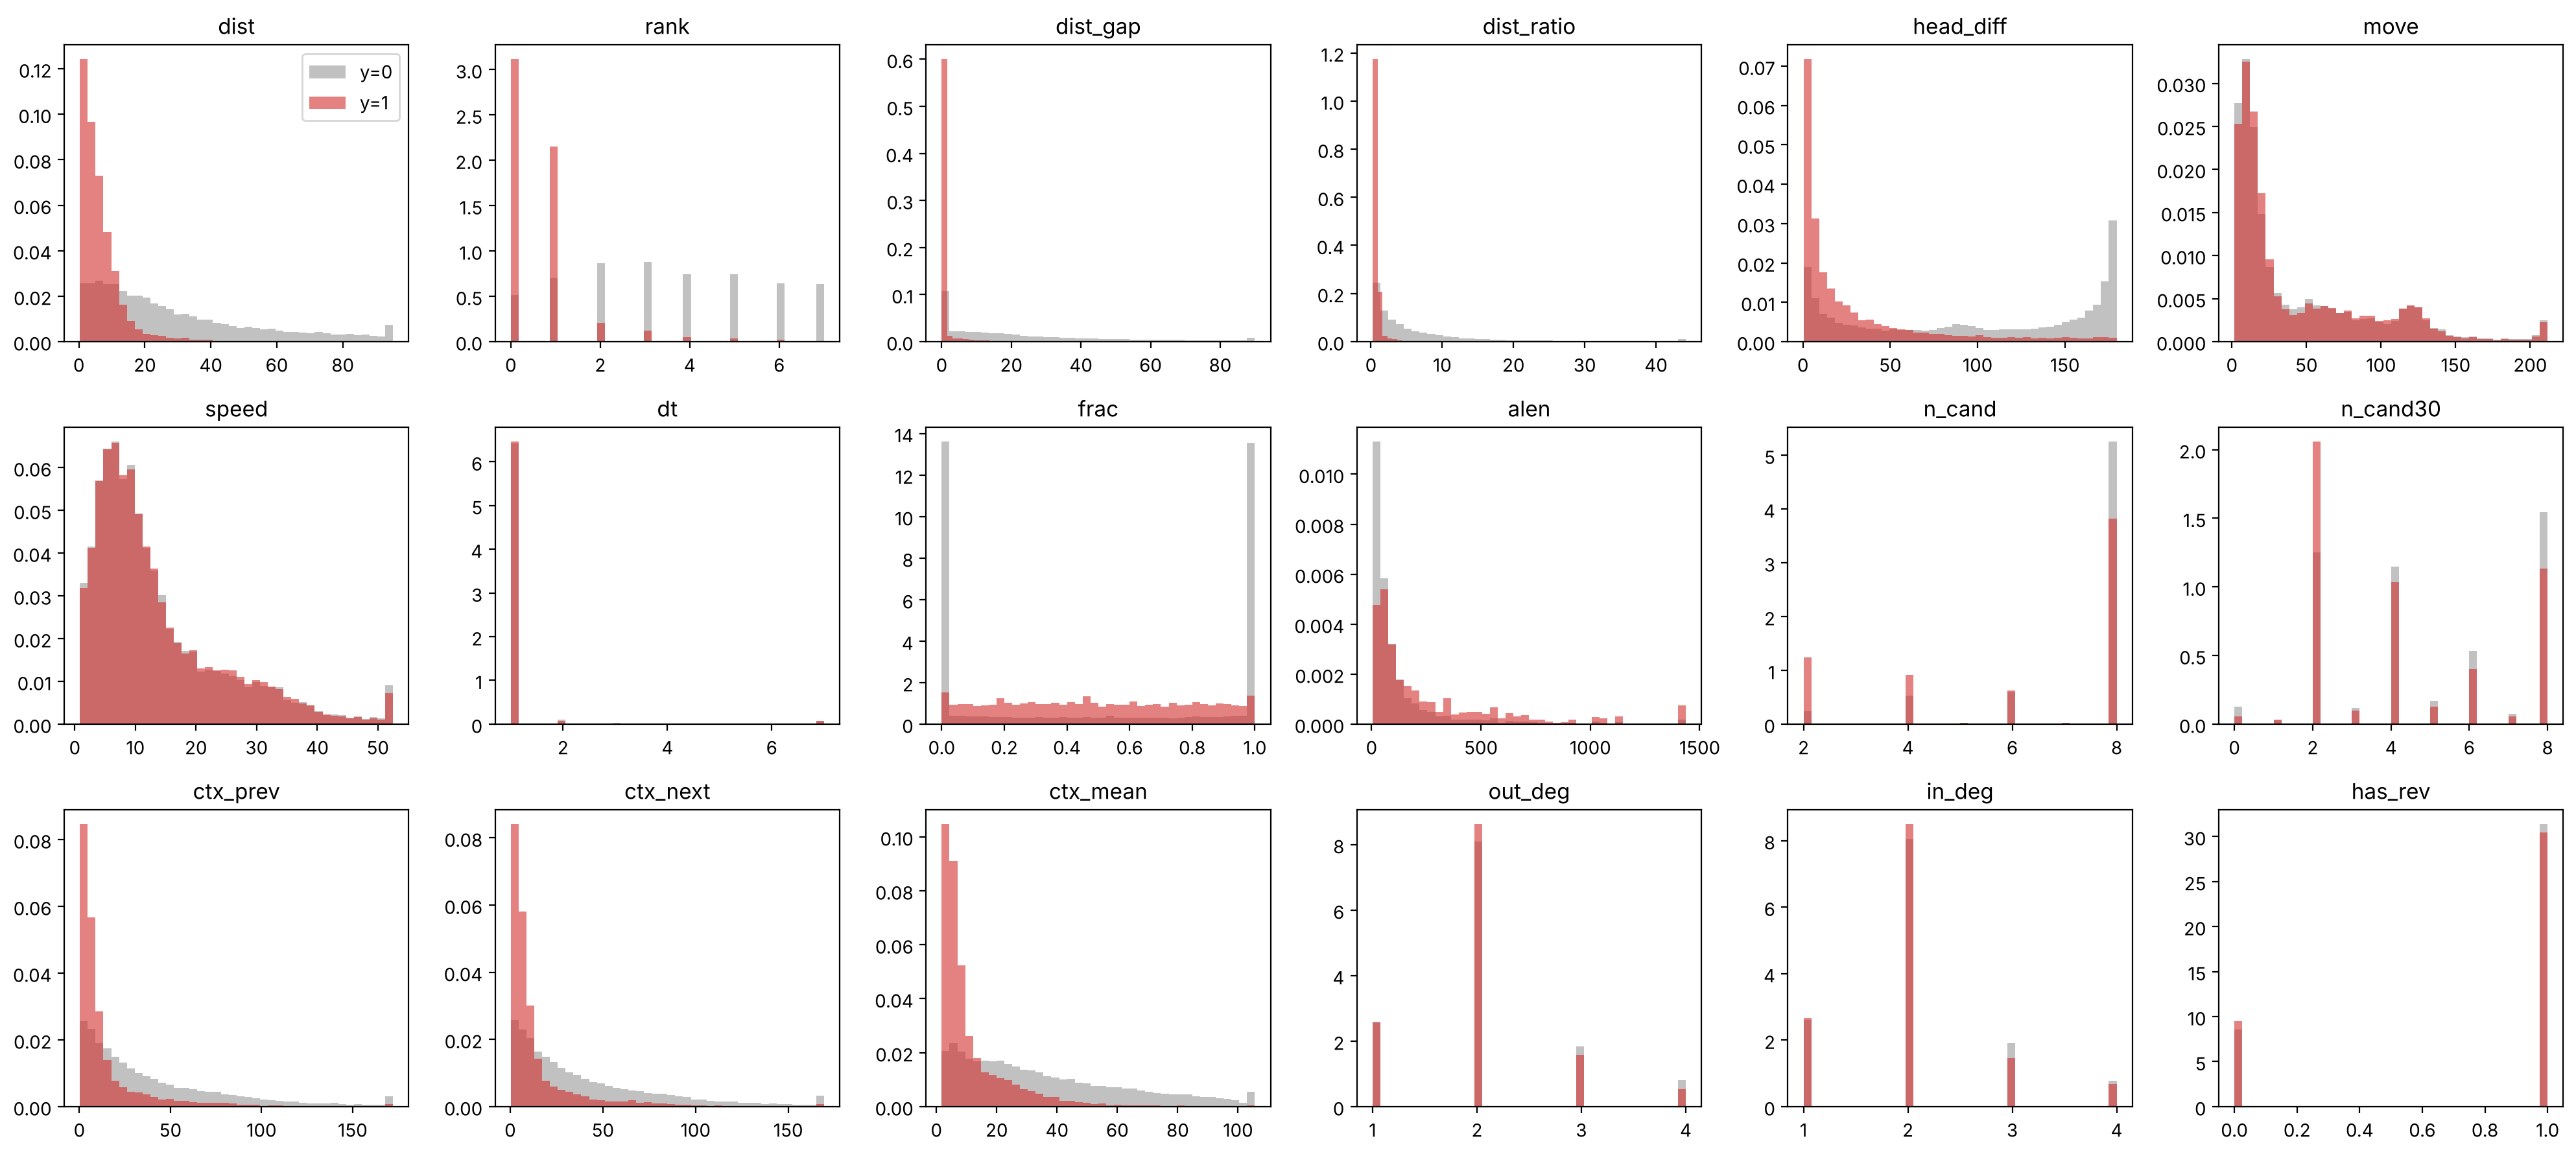

In [4]:
fig, axes = plt.subplots(3, 6, figsize=(20, 9))
for ax, f in zip(axes.ravel(), features.FEATURES):
    lo, hi = df[f].quantile([.01, .99])
    for y, c in [(0, "#999"), (1, "#d32f2f")]:
        ax.hist(df.loc[df.y == y, f].clip(lo, hi), bins=40, alpha=.6, color=c, density=True, label=f"y={y}")
    ax.set_title(f)
axes[0, 0].legend()
plt.tight_layout(); plt.savefig(f"{FIG}/feature_distributions.png", dpi=110)

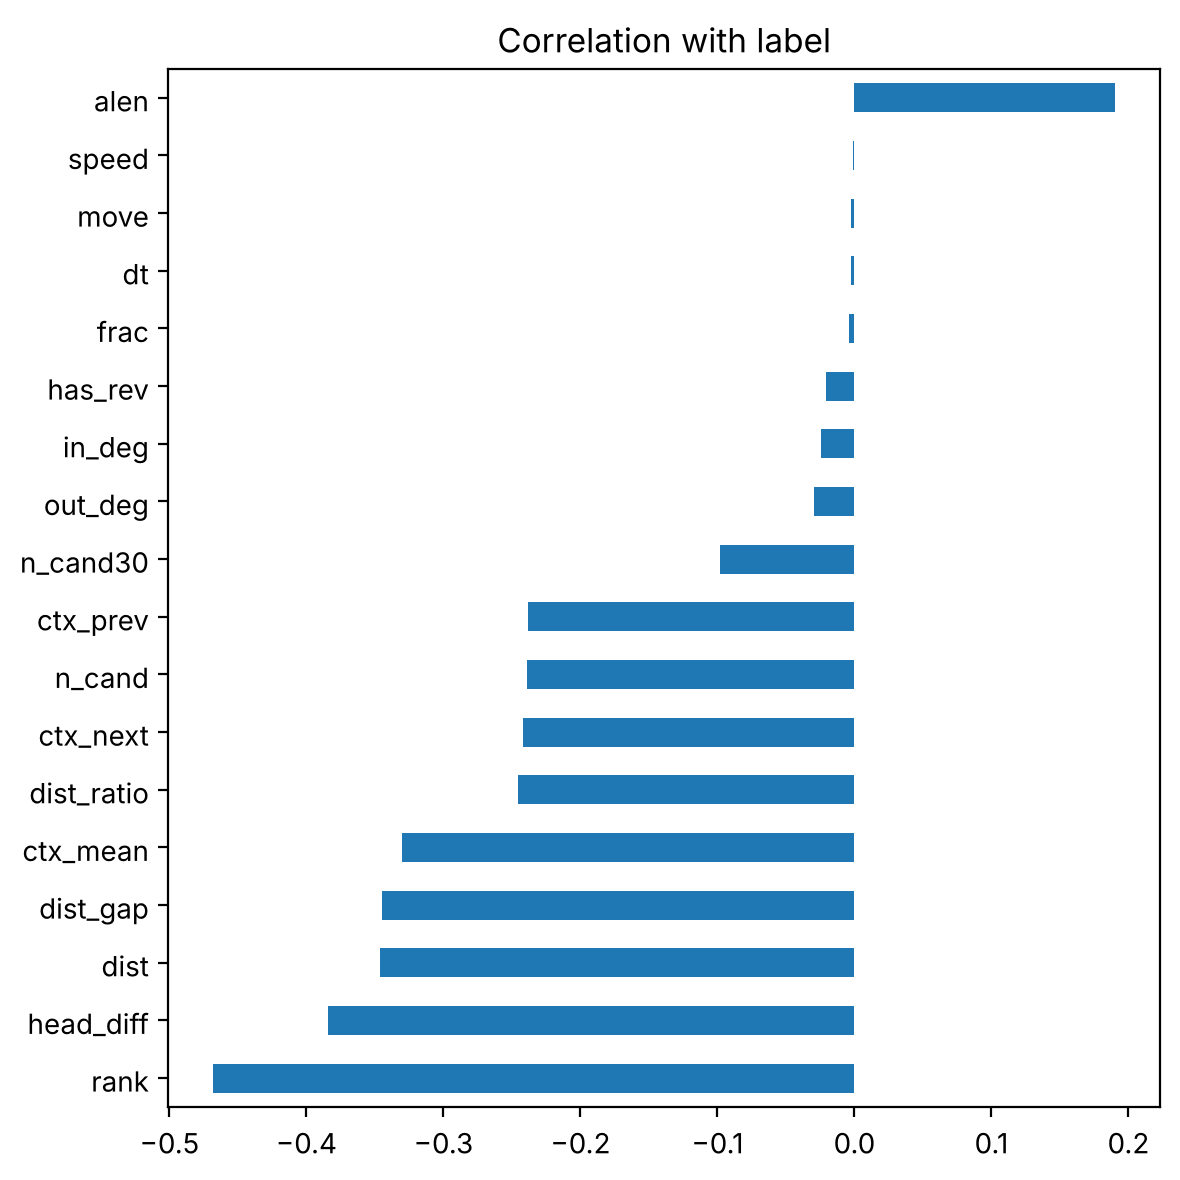

In [5]:
corr = df[features.FEATURES + ["y"]].corr()["y"].drop("y").sort_values()
corr.plot.barh(figsize=(6, 6), title="Correlation with label"); plt.tight_layout()
plt.savefig(f"{FIG}/feature_label_corr.png", dpi=120)

In [6]:
tr = io.load_trip("train", "00000010")
m = viz.trip_map(tr, ref=tr["route"])
m.save("../outputs/maps/eda_trip_00000010.html")